In [3]:
from google.colab import drive
drive.mount('/content/drive')

# Instalasi library yang dibutuhkan (AutoGluon untuk Chronos-Bolt)
!pip install -q autogluon.timeseries openpyxl statsmodels scikit-learn seaborn matplotlib

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Konfigurasi Path dan Load Data

In [5]:
import os
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Path sesuai struktur Google Drive
BASE_DIR = "/content/drive/MyDrive/Tugas kuliah/ADL"
FILE_PATH = os.path.join(BASE_DIR, "Panama_beban_listrik_per_jam_2015-2020_.xlsx")
OUTPUT_DIR = os.path.join(BASE_DIR, "dashboard_artifacts")
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Load data
df = pd.read_excel(FILE_PATH, sheet_name="data")
df['datetime'] = pd.to_datetime(df['datetime'])
df = df.sort_values('datetime').reset_index(drop=True)

# Ekstraksi fitur waktu untuk kebutuhan EDA
df['year'] = df['datetime'].dt.year
df['month'] = df['datetime'].dt.month
df['hour'] = df['datetime'].dt.hour
df['dayofweek'] = df['datetime'].dt.dayofweek # 0=Senin, 6=Minggu

print(f"Dimensi data : {df.shape}")
print(f"Periode      : {df['datetime'].min()} s.d. {df['datetime'].max()}")
print(f"Missing value: {df['nat_demand'].isnull().sum()}")
print(f"Interval unik: {df['datetime'].diff().dropna().unique()}")
df[['datetime', 'nat_demand']].head()

Dimensi data : (48048, 21)
Periode      : 2015-01-03 01:00:00 s.d. 2020-06-27 00:00:00
Missing value: 0
Interval unik: <TimedeltaArray>
['0 days 01:00:00']
Length: 1, dtype: timedelta64[ns]


,datetime,nat_demand
0,2015-01-03 01:00:00,970.3450
1,2015-01-03 02:00:00,912.1755
2,2015-01-03 03:00:00,900.2688
3,2015-01-03 04:00:00,889.9538
4,2015-01-03 05:00:00,893.6865


Analisis deksriptif, deteksi outlier, dampak covid-19 dan uji ADF

In [6]:
from statsmodels.tsa.stattools import adfuller

y = df['nat_demand']

# 1. Statistik Deskriptif Lengkap
desc_stats = pd.DataFrame({
    'Metrik': ['Jumlah Data', 'Rata-rata (Mean)', 'Standar Deviasi', 'Minimum',
               'Q1 (25%)', 'Median (50%)', 'Q3 (75%)', 'Maksimum', 'Skewness', 'Kurtosis'],
    'Nilai': [len(y), y.mean(), y.std(), y.min(), y.quantile(0.25),
              y.median(), y.quantile(0.75), y.max(), y.skew(), y.kurt()]
})
print("=== STATISTIK DESKRIPTIF (nat_demand - MWh) ===")
display(desc_stats.round(2))

# 2. Ringkasan per Tahun
print("\n=== RINGKASAN BEBAN LISTRIK PER TAHUN ===")
yearly_summary = df.groupby('year')['nat_demand'].agg(['count', 'mean', 'std', 'min', 'max']).round(2)
display(yearly_summary)

# 3. Deteksi Outlier (Metode IQR)
Q1, Q3 = y.quantile(0.25), y.quantile(0.75)
IQR = Q3 - Q1
low_bound, high_bound = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
outliers_low = df[df['nat_demand'] < low_bound]
outliers_high = df[df['nat_demand'] > high_bound]

print(f"\n=== DETEKSI OUTLIER (Batas Bawah: {low_bound:.2f}, Batas Atas: {high_bound:.2f}) ===")
print(f"Jumlah Outlier Bawah: {len(outliers_low)} | Outlier Atas: {len(outliers_high)}")
display(outliers_low[['datetime', 'nat_demand']])

# 4. Analisis Pergeseran Struktural COVID-19 (Mar-Jun 2019 vs Mar-Jun 2020)
m2019 = df[(df['year'] == 2019) & (df['month'].isin([3, 4, 5, 6]))]['nat_demand'].mean()
m2020 = df[(df['year'] == 2020) & (df['month'].isin([3, 4, 5, 6]))]['nat_demand'].mean()
pct_change = (m2020 - m2019) / m2019 * 100
print(f"\n=== DAMPAK COVID-19 (MARET–JUNI) ===")
print(f"Rata-rata 2019: {m2019:.2f} MWh | Rata-rata 2020: {m2020:.2f} MWh | Perubahan: {pct_change:.2f}%")

# 5. Uji Stasioneritas (Augmented Dickey-Fuller Test pada rata-rata harian)
daily_series = df.set_index('datetime')['nat_demand'].resample('D').mean()
adf_stat, p_val, _, _, crit_vals, _ = adfuller(daily_series.dropna())
print(f"\n=== UJI STASIONERITAS (ADF TEST - HARIAN) ===")
print(f"ADF Statistic: {adf_stat:.4f} | p-value: {p_val:.4e}")
print(f"Critical Values: {crit_vals}")

=== STATISTIK DESKRIPTIF (nat_demand - MWh) ===


,Metrik,Nilai
0,Jumlah Data,48048.00
1,Rata-rata (Mean),1182.87
2,Standar Deviasi,192.07
3,Minimum,85.19
4,Q1 (25%),1020.06
5,Median (50%),1168.43
6,Q3 (75%),1327.56
7,Maksimum,1754.88
8,Skewness,0.25
9,Kurtosis,-0.82



=== RINGKASAN BEBAN LISTRIK PER TAHUN ===


,count,mean,std,min,max
year,,,,,
2015,8711,1131.53,194.15,509.84,1645.48
2016,8784,1157.19,190.29,744.43,1615.25
2017,8760,1182.32,188.96,380.59,1635.92
2018,8760,1205.68,185.45,826.78,1635.54
2019,8760,1243.58,189.14,85.19,1721.52
2020,4273,1170.23,176.12,821.85,1754.88



=== DETEKSI OUTLIER (Batas Bawah: 558.80, Batas Atas: 1788.82) ===
Jumlah Outlier Bawah: 7 | Outlier Atas: 0


,datetime,nat_demand
520,2015-01-24 17:00:00,509.8358
21755,2017-06-27 12:00:00,380.5936
35483,2019-01-20 12:00:00,85.1925
35484,2019-01-20 13:00:00,135.7636
35485,2019-01-20 14:00:00,263.6183
35486,2019-01-20 15:00:00,417.4492
35487,2019-01-20 16:00:00,475.8024



=== DAMPAK COVID-19 (MARET–JUNI) ===
Rata-rata 2019: 1265.11 MWh | Rata-rata 2020: 1117.91 MWh | Perubahan: -11.64%

=== UJI STASIONERITAS (ADF TEST - HARIAN) ===
ADF Statistic: -3.5594 | p-value: 6.5874e-03
Critical Values: {'1%': np.float64(-3.4336636717018405), '5%': np.float64(-2.8630037919874423), '10%': np.float64(-2.567549261922421)}


Visualisasi EDA lengkap (tren, musiman ganda, boxplot, STL, dan ACF/PACF)

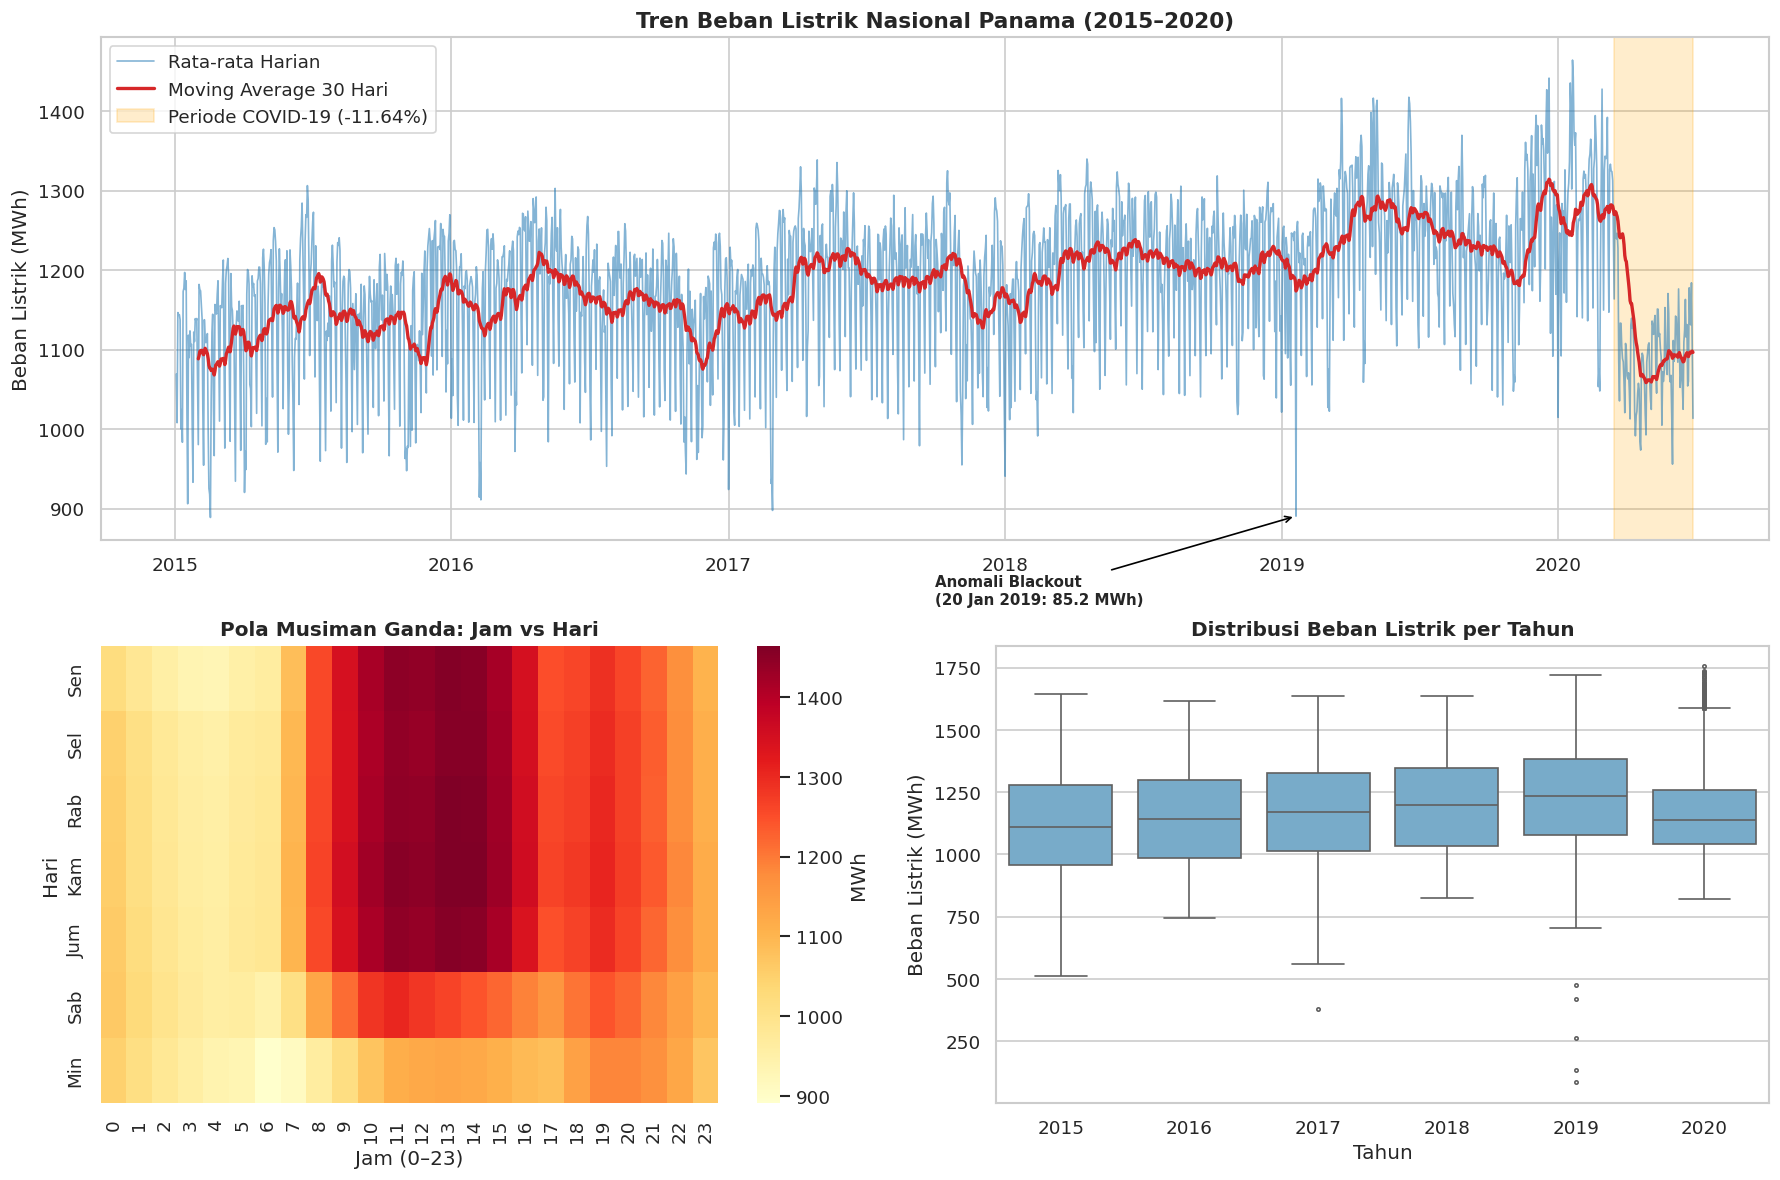

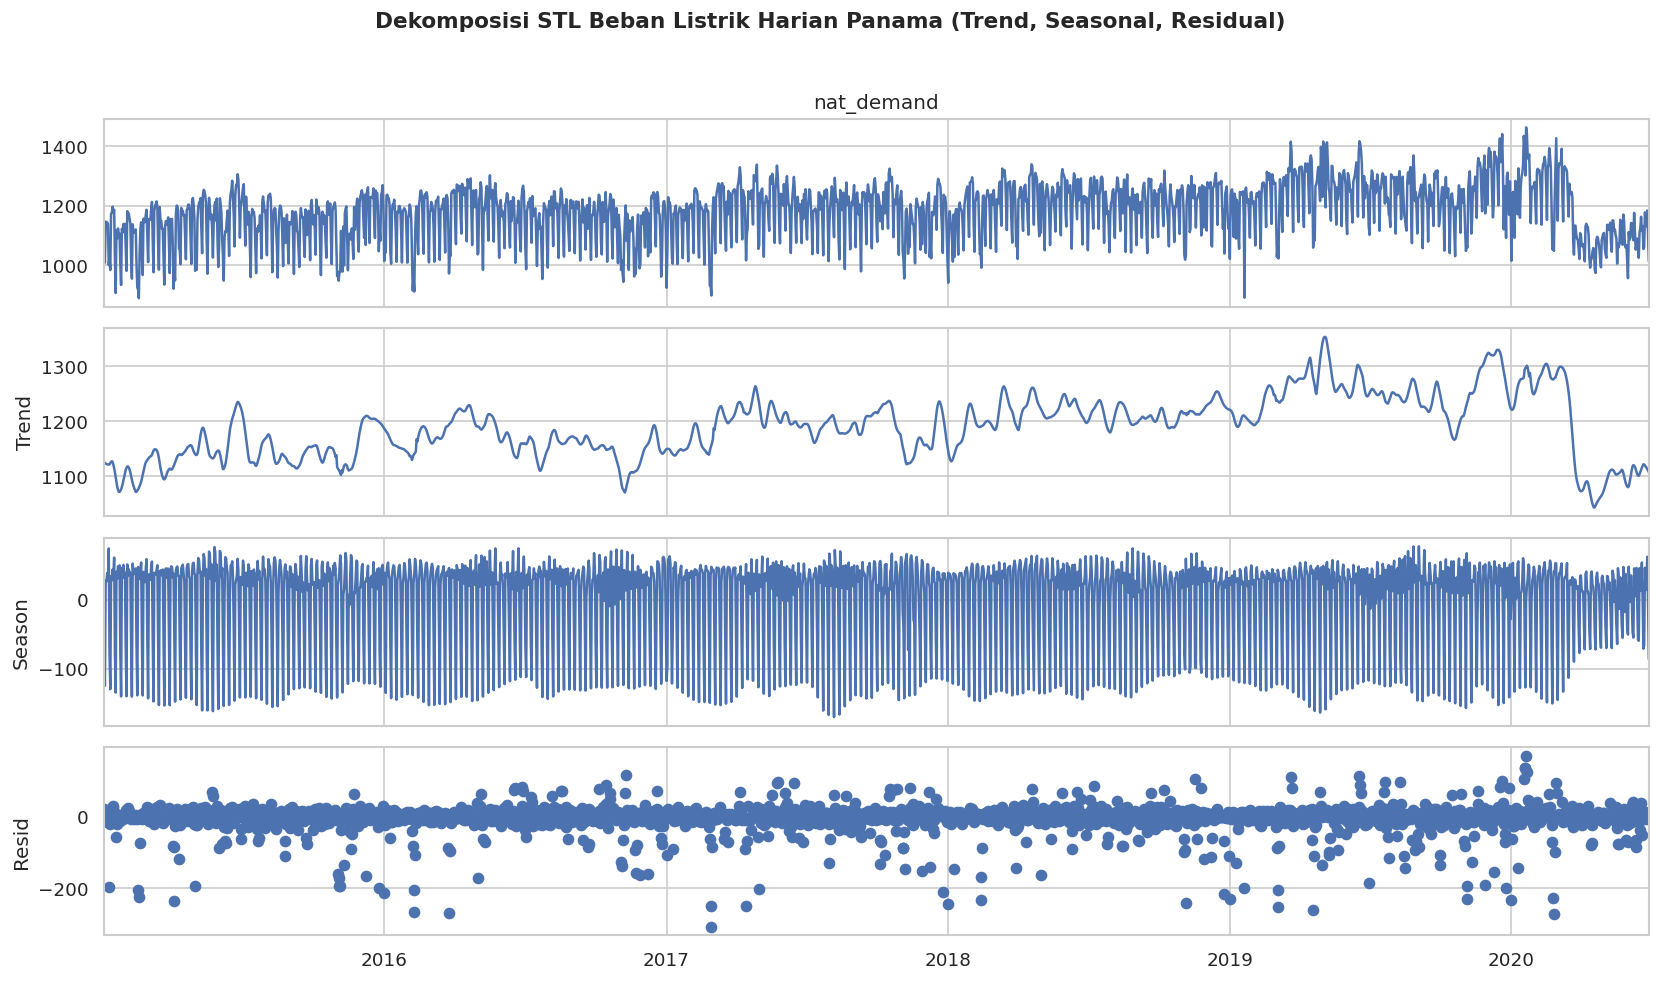

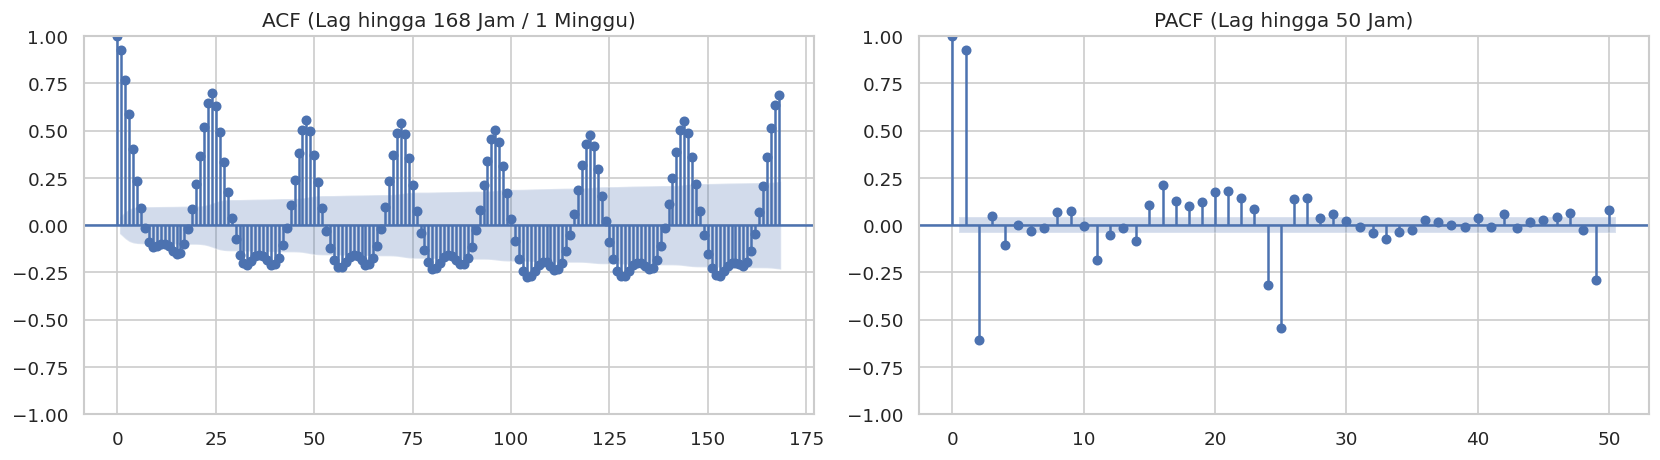

In [7]:
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 120

# --- PLOT 1: Dashboard EDA (Tren, Heatmap Musiman Ganda, Boxplot Tahunan) ---
fig = plt.figure(figsize=(15, 10))
gs = fig.add_gridspec(2, 2, height_ratios=[1.1, 1])

# Panel A: Tren Harian + MA30 + COVID-19 + Blackout
ax1 = fig.add_subplot(gs[0, :])
ax1.plot(daily_series.index, daily_series.values, color='#1f77b4', alpha=0.55, lw=1, label='Rata-rata Harian')
ax1.plot(daily_series.index, daily_series.rolling(30).mean(), color='#d62728', lw=2, label='Moving Average 30 Hari')
ax1.axvspan(pd.Timestamp('2020-03-15'), daily_series.index.max(), color='orange', alpha=0.2, label='Periode COVID-19 (-11.64%)')
ax1.annotate('Anomali Blackout\n(20 Jan 2019: 85.2 MWh)',
             xy=(pd.Timestamp('2019-01-20'), daily_series.loc['2019-01-20']),
             xytext=(pd.Timestamp('2017-10-01'), 780),
             arrowprops=dict(arrowstyle='->', color='black'), fontsize=9, fontweight='bold')
ax1.set_title('Tren Beban Listrik Nasional Panama (2015–2020)', fontsize=13, fontweight='bold')
ax1.set_ylabel('Beban Listrik (MWh)')
ax1.legend(loc='upper left')

# Panel B: Heatmap Jam vs Hari
ax2 = fig.add_subplot(gs[1, 0])
pivot_hm = df.pivot_table(values='nat_demand', index='dayofweek', columns='hour', aggfunc='mean')
pivot_hm.index = ['Sen', 'Sel', 'Rab', 'Kam', 'Jum', 'Sab', 'Min']
sns.heatmap(pivot_hm, cmap='YlOrRd', ax=ax2, cbar_kws={'label': 'MWh'})
ax2.set_title('Pola Musiman Ganda: Jam vs Hari', fontsize=12, fontweight='bold')
ax2.set_xlabel('Jam (0–23)')
ax2.set_ylabel('Hari')

# Panel C: Boxplot per Tahun
ax3 = fig.add_subplot(gs[1, 1])
sns.boxplot(data=df, x='year', y='nat_demand', ax=ax3, color='#6baed6', fliersize=2)
ax3.set_title('Distribusi Beban Listrik per Tahun', fontsize=12, fontweight='bold')
ax3.set_xlabel('Tahun')
ax3.set_ylabel('Beban Listrik (MWh)')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'eda_overview.png'), bbox_inches='tight')
plt.show()

# --- PLOT 2: Dekomposisi STL (Rata-rata Harian, Periode Mingguan = 7) ---
stl_res = STL(daily_series, period=7, robust=True).fit()
fig_stl = stl_res.plot()
fig_stl.set_size_inches(14, 8)
fig_stl.suptitle('Dekomposisi STL Beban Listrik Harian Panama (Trend, Seasonal, Residual)', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'eda_stl_decomposition.png'), bbox_inches='tight')
plt.show()

# --- PLOT 3: ACF & PACF (Data Per Jam, 1000 Observasi Terakhir, Lag 168 Jam) ---
fig_corr, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(df['nat_demand'].iloc[-2000:], lags=168, ax=axes[0], title='ACF (Lag hingga 168 Jam / 1 Minggu)')
plot_pacf(df['nat_demand'].iloc[-2000:], lags=50, ax=axes[1], method='ywm', title='PACF (Lag hingga 50 Jam)')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'eda_acf_pacf.png'), bbox_inches='tight')
plt.show()

Pemodelan metode klasik (baseline)-24, 168, dan 720 jam

In [8]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

def calc_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = root_mean_squared_error(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    return mae, rmse, mape

def make_fourier_features(index_arr, period, order):
    feats = []
    for k in range(1, order + 1):
        feats.append(np.sin(2 * np.pi * k * index_arr / period))
        feats.append(np.cos(2 * np.pi * k * index_arr / period))
    return np.column_stack(feats)

series = df['nat_demand'].values
dates = df['datetime'].values
horizons = [24, 168, 720]

classical_metrics = []
classical_forecasts = []

for h in horizons:
    train = series[:-h]
    test = series[-h:]
    test_dates = dates[-h:]

    # 1. Seasonal Naive (Lag 168 jam / 1 minggu)
    pred_snaive = np.array([train[-168 + (i % 168)] for i in range(h)])

    # 2. Holt-Winters / Triple Exponential Smoothing (4 minggu terakhir, s=24)
    hw_model = ExponentialSmoothing(
        train[-24*28:], trend='add', damped_trend=True, seasonal='add', seasonal_periods=24
    ).fit(optimized=True)
    pred_hw = hw_model.forecast(h)

    # 3. Harmonic Regression (Fourier 24h + 168h dengan Ridge, 8 minggu terakhir)
    win = 24 * 56
    t_tr = np.arange(win)
    t_te = np.arange(win, win + h)
    X_tr = np.hstack([make_fourier_features(t_tr, 24, 4), make_fourier_features(t_tr, 168, 4)])
    X_te = np.hstack([make_fourier_features(t_te, 24, 4), make_fourier_features(t_te, 168, 4)])
    pred_fourier = Ridge(alpha=1.0).fit(X_tr, train[-win:]).predict(X_te)

    models_dict = {
        'Seasonal Naive (168h)': pred_snaive,
        'Holt-Winters (ETS)': pred_hw,
        'Harmonic Regression (Fourier)': pred_fourier
    }

    for m_name, y_pred in models_dict.items():
        mae, rmse, mape = calc_metrics(test, y_pred)
        classical_metrics.append({
            'Horizon': f'{h} Jam', 'Kategori': 'Klasik', 'Model': m_name,
            'MAE': mae, 'RMSE': rmse, 'MAPE (%)': mape
        })
        classical_forecasts.append(pd.DataFrame({
            'Horizon': f'{h} Jam', 'Kategori': 'Klasik', 'Model': m_name,
            'timestamp': test_dates, 'actual': test, 'pred_mean': y_pred,
            'pred_p10': np.nan, 'pred_p90': np.nan
        }))

df_classical_metrics = pd.DataFrame(classical_metrics)
df_classical_forecasts = pd.concat(classical_forecasts, ignore_index=True)

print("=== HASIL EVALUASI METODE KLASIK ===")
display(df_classical_metrics.round(2))

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/holtwinters/model.py:1065: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  res = self._optimize_parameters(res, use_brute, method, minimize_kwargs)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/holtwinters/model.py:1065: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  res = self._optimize_parameters(res, use_brute, method, minimize_kwargs)


=== HASIL EVALUASI METODE KLASIK ===


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/holtwinters/model.py:1065: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  res = self._optimize_parameters(res, use_brute, method, minimize_kwargs)


,Horizon,Kategori,Model,MAE,RMSE,MAPE (%)
0,24 Jam,Klasik,Seasonal Naive (168h),40.24,46.29,3.66
1,24 Jam,Klasik,Holt-Winters (ETS),35.45,39.47,3.23
2,24 Jam,Klasik,Harmonic Regression (Fourier),32.66,37.55,2.94
3,168 Jam,Klasik,Seasonal Naive (168h),54.06,70.44,4.70
4,168 Jam,Klasik,Holt-Winters (ETS),71.80,87.77,6.23
5,168 Jam,Klasik,Harmonic Regression (Fourier),58.97,75.30,5.07
6,720 Jam,Klasik,Seasonal Naive (168h),56.99,72.41,5.21
7,720 Jam,Klasik,Holt-Winters (ETS),103.81,124.58,9.11
8,720 Jam,Klasik,Harmonic Regression (Fourier),60.39,77.91,5.37


Pemodelan transfer learning (amazon chronos-bolt: zero-shot vs fine-tuned)

In [9]:
from autogluon.timeseries import TimeSeriesDataFrame, TimeSeriesPredictor

# Siapkan format TimeSeriesDataFrame untuk AutoGluon
ts_df = pd.DataFrame({
    'item_id': 'Panama_Grid',
    'timestamp': df['datetime'],
    'target': df['nat_demand']
})

chronos_metrics = []
chronos_forecasts = []

for h in horizons:
    print(f"\n==================== HORIZON: {h} JAM ====================")
    train_ag = TimeSeriesDataFrame.from_data_frame(ts_df.iloc[:-h])
    test_actual = ts_df.iloc[-h:].copy()

    # A. Chronos-Bolt (Zero-Shot)
    print(f"[1/2] Menjalankan Chronos-Bolt Zero-Shot ({h} Jam)...")
    predictor_zs = TimeSeriesPredictor(
        prediction_length=h, freq="h", eval_metric="MAE", path=f"ag_chronos_zs_{h}"
    ).fit(
        train_ag,
        hyperparameters={"Chronos": {"model_path": "bolt_small"}},
        time_limit=120,
        verbosity=1
    )
    pred_zs = predictor_zs.predict(train_ag).reset_index()

    # B. Chronos-Bolt (Fine-Tuned pada data Panama)
    print(f"[2/2] Menjalankan Chronos-Bolt Fine-Tuning ({h} Jam)...")
    predictor_ft = TimeSeriesPredictor(
        prediction_length=h, freq="h", eval_metric="MAE", path=f"ag_chronos_ft_{h}"
    ).fit(
        train_ag,
        hyperparameters={
            "Chronos": {
                "model_path": "bolt_small",
                "fine_tune": True,
                "fine_tune_steps": 500,
                "fine_tune_lr": 1e-4
            }
        },
        time_limit=300,
        verbosity=1
    )
    pred_ft = predictor_ft.predict(train_ag).reset_index()

    for m_name, p_df in [("Chronos-Bolt Zero-Shot", pred_zs), ("Chronos-Bolt Fine-Tuned", pred_ft)]:
        mae, rmse, mape = calc_metrics(test_actual['target'].values, p_df['mean'].values)
        chronos_metrics.append({
            'Horizon': f'{h} Jam', 'Kategori': 'Transfer Learning', 'Model': m_name,
            'MAE': mae, 'RMSE': rmse, 'MAPE (%)': mape
        })
        chronos_forecasts.append(pd.DataFrame({
            'Horizon': f'{h} Jam', 'Kategori': 'Transfer Learning', 'Model': m_name,
            'timestamp': test_actual['timestamp'].values,
            'actual': test_actual['target'].values,
            'pred_mean': p_df['mean'].values,
            'pred_p10': p_df['0.1'].values,
            'pred_p90': p_df['0.9'].values
        }))

df_chronos_metrics = pd.DataFrame(chronos_metrics)
df_chronos_forecasts = pd.concat(chronos_forecasts, ignore_index=True)

print("\n=== HASIL EVALUASI CHRONOS-BOLT ===")
display(df_chronos_metrics.round(2))


==================== HORIZON: 24 JAM ====================
[1/2] Menjalankan Chronos-Bolt Zero-Shot (24 Jam)...


config.json:   0%|          | 0.00/1.12k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  191MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/143 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/143 [00:00<?, ?it/s]

... (16 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/143 [00:00<?, ?it/s]


=== HASIL EVALUASI CHRONOS-BOLT ===


,Horizon,Kategori,Model,MAE,RMSE,MAPE (%)
0,24 Jam,Transfer Learning,Chronos-Bolt Zero-Shot,68.46,80.15,6.16
1,24 Jam,Transfer Learning,Chronos-Bolt Fine-Tuned,73.95,86.33,6.61
2,168 Jam,Transfer Learning,Chronos-Bolt Zero-Shot,48.00,58.36,4.14
3,168 Jam,Transfer Learning,Chronos-Bolt Fine-Tuned,50.13,61.04,4.32
4,720 Jam,Transfer Learning,Chronos-Bolt Zero-Shot,58.97,74.24,5.17
5,720 Jam,Transfer Learning,Chronos-Bolt Fine-Tuned,59.34,74.16,5.26


Perbandingan Lengkap (Tabel dan Visualisasi semua model)

=== TABEL PERBANDINGAN LENGKAP (DIURUTKAN BERDASARKAN HORIZON & MAPE) ===


,Horizon,Kategori,Model,MAE,RMSE,MAPE (%)
11,168 Jam,Transfer Learning,Chronos-Bolt Zero-Shot,48.00,58.36,4.14
12,168 Jam,Transfer Learning,Chronos-Bolt Fine-Tuned,50.13,61.04,4.32
3,168 Jam,Klasik,Seasonal Naive (168h),54.06,70.44,4.70
5,168 Jam,Klasik,Harmonic Regression (Fourier),58.97,75.30,5.07
4,168 Jam,Klasik,Holt-Winters (ETS),71.80,87.77,6.23
2,24 Jam,Klasik,Harmonic Regression (Fourier),32.66,37.55,2.94
1,24 Jam,Klasik,Holt-Winters (ETS),35.45,39.47,3.23
0,24 Jam,Klasik,Seasonal Naive (168h),40.24,46.29,3.66
9,24 Jam,Transfer Learning,Chronos-Bolt Zero-Shot,68.46,80.15,6.16
10,24 Jam,Transfer Learning,Chronos-Bolt Fine-Tuned,73.95,86.33,6.61


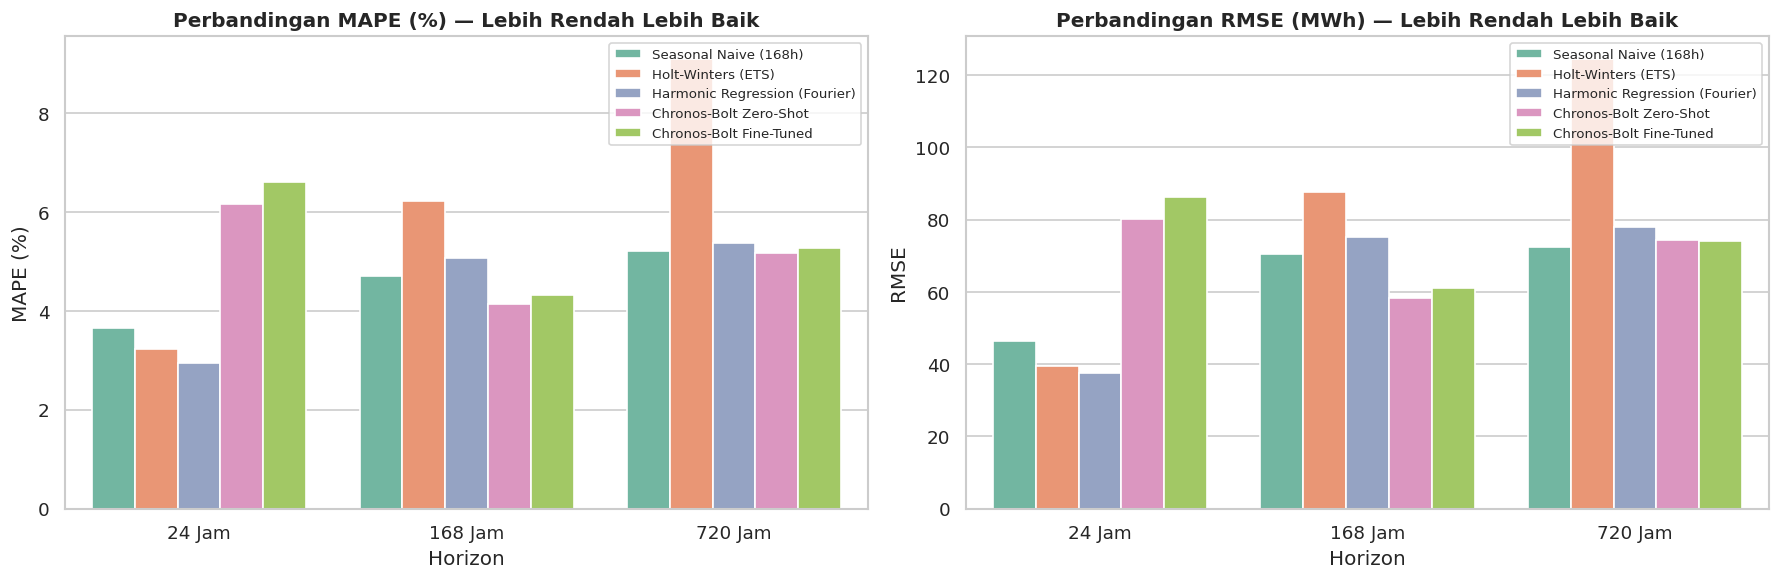

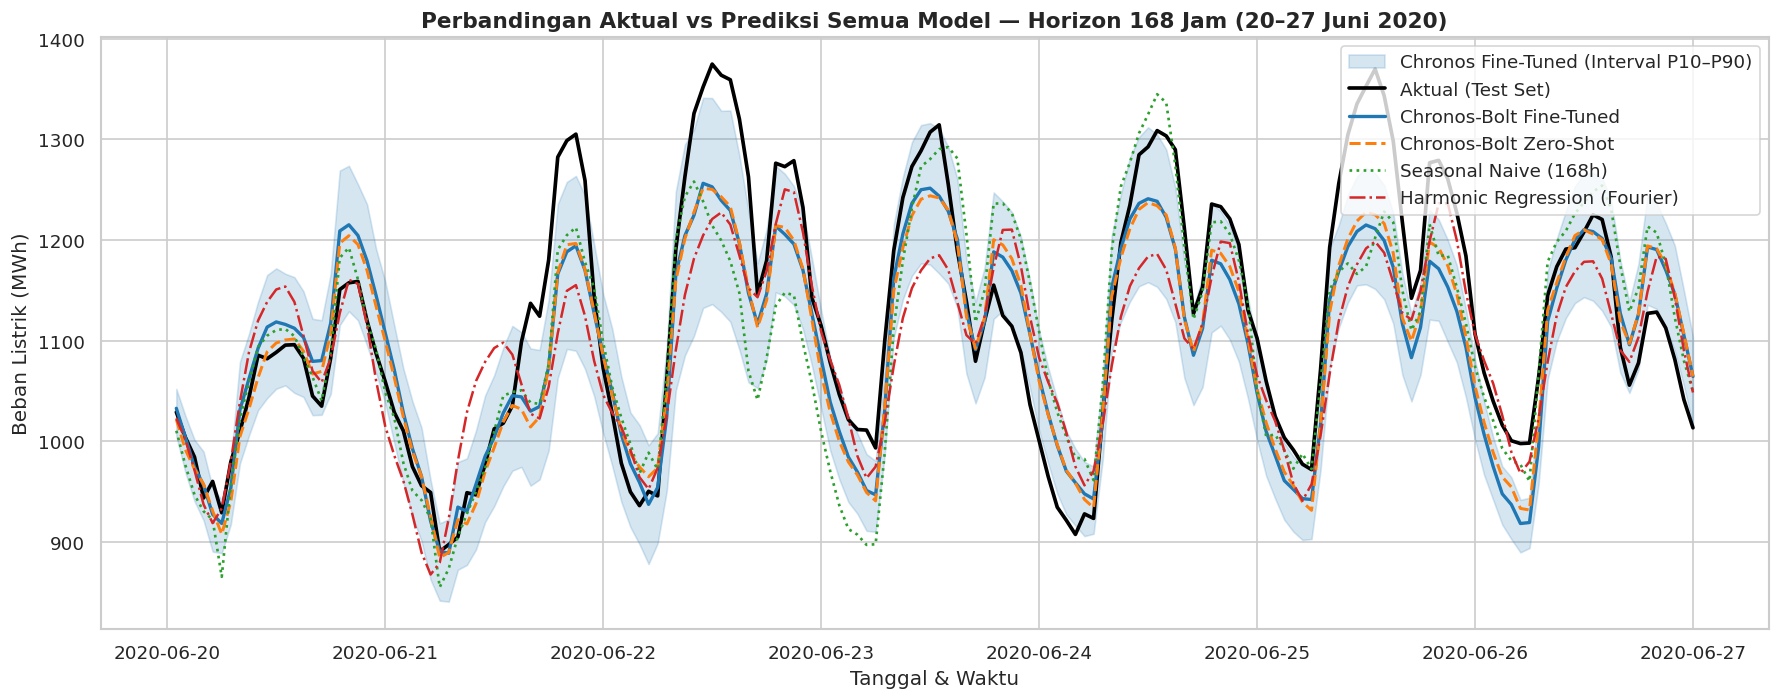

In [10]:
# Gabungkan hasil Klasik & Transfer Learning
all_metrics_df = pd.concat([df_classical_metrics, df_chronos_metrics], ignore_index=True)
all_forecasts_df = pd.concat([df_classical_forecasts, df_chronos_forecasts], ignore_index=True)

print("=== TABEL PERBANDINGAN LENGKAP (DIURUTKAN BERDASARKAN HORIZON & MAPE) ===")
summary_table = all_metrics_df.sort_values(by=['Horizon', 'MAPE (%)'])
display(summary_table.round(2))

# --- VISUALISASI 1: Bar Chart Perbandingan MAPE & RMSE per Horizon ---
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(data=all_metrics_df, x='Horizon', y='MAPE (%)', hue='Model', ax=axes[0], palette='Set2')
axes[0].set_title('Perbandingan MAPE (%) — Lebih Rendah Lebih Baik', fontsize=12, fontweight='bold')
axes[0].legend(loc='upper right', fontsize=8)

sns.barplot(data=all_metrics_df, x='Horizon', y='RMSE', hue='Model', ax=axes[1], palette='Set2')
axes[1].set_title('Perbandingan RMSE (MWh) — Lebih Rendah Lebih Baik', fontsize=12, fontweight='bold')
axes[1].legend(loc='upper right', fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'model_comparison_metrics.png'), bbox_inches='tight')
plt.show()

# --- VISUALISASI 2: Plot Aktual vs Prediksi pada Horizon 168 Jam (7 Hari) ---
sub_168 = all_forecasts_df[all_forecasts_df['Horizon'] == '168 Jam']
actual_168 = sub_168[sub_168['Model'] == 'Chronos-Bolt Fine-Tuned']

plt.figure(figsize=(15, 6))
# Interval prediksi P10-P90 dari Chronos Fine-Tuned
plt.fill_between(actual_168['timestamp'], actual_168['pred_p10'], actual_168['pred_p90'],
                 color='#1f77b4', alpha=0.18, label='Chronos Fine-Tuned (Interval P10–P90)')

# Garis Aktual
plt.plot(actual_168['timestamp'], actual_168['actual'], color='black', lw=2.2, label='Aktual (Test Set)')

# Garis Prediksi Model Terbaik Klasik vs Chronos
plot_models = [
    ('Chronos-Bolt Fine-Tuned', '#1f77b4', '-', 2.0),
    ('Chronos-Bolt Zero-Shot', '#ff7f0e', '--', 1.8),
    ('Seasonal Naive (168h)', '#2ca02c', ':', 1.6),
    ('Harmonic Regression (Fourier)', '#d62728', '-.', 1.5)
]
for m_name, col, ls, lw in plot_models:
    m_df = sub_168[sub_168['Model'] == m_name]
    plt.plot(m_df['timestamp'], m_df['pred_mean'], color=col, linestyle=ls, lw=lw, label=m_name)

plt.title('Perbandingan Aktual vs Prediksi Semua Model — Horizon 168 Jam (20–27 Juni 2020)', fontsize=13, fontweight='bold')
plt.xlabel('Tanggal & Waktu')
plt.ylabel('Beban Listrik (MWh)')
plt.legend(loc='upper right')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'forecast_comparison_168h.png'), bbox_inches='tight')
plt.show()

Ekspor semua artefak ke folder

In [11]:
# Simpan tabel metrik dan prediksi lengkap ke folder dashboard_artifacts
all_metrics_df.to_csv(os.path.join(OUTPUT_DIR, "all_models_metrics.csv"), index=False)
all_forecasts_df.to_csv(os.path.join(OUTPUT_DIR, "all_models_forecasts.csv"), index=False)
df_chronos_metrics.to_csv(os.path.join(OUTPUT_DIR, "chronos_metrics.csv"), index=False)
df_chronos_forecasts.to_csv(os.path.join(OUTPUT_DIR, "chronos_forecasts.csv"), index=False)

print("Semua file berhasil disimpan di:", OUTPUT_DIR)
print("Daftar file di dashboard_artifacts:")
for f in sorted(os.listdir(OUTPUT_DIR)):
    print(" -", f)

Semua file berhasil disimpan di: /content/drive/MyDrive/Tugas kuliah/ADL/dashboard_artifacts
Daftar file di dashboard_artifacts:
 - all_models_forecasts.csv
 - all_models_metrics.csv
 - cdsr_core.py
 - chronos_forecasts.csv
 - chronos_metrics.csv
 - eda_acf_pacf.png
 - eda_overview.png
 - eda_stl_decomposition.png
 - forecast_comparison_168h.png
 - model_comparison_metrics.png
 - models
